# Relatório da Solução

In [6]:
import pandas as pd

from matplotlib import pyplot as plt

import seaborn as sns

from pathlib import Path

In [7]:
## Função para padronizar os gráficos a serem analizados usando principalmente os resultados
# da função build_diagnostics

def plot_model_diagnostics(df_diagnostics,comparison_df):

    fig, axes = plt.subplot_mosaic(
        [
            ['B', 'B', 'C', 'C'],
            ['.', 'A', 'A', '.']
        ],
        figsize=(15,10),
    )

    # 1. Temperatura real vs. prevista do Modelo CatBoost nos dados de Teste

    sns.scatterplot(
        data=df_diagnostics,
        x='actual',
        y='predicted',
        alpha=0.3,
        s=18,
        ax=axes['A']
    )

    min_temp = df_diagnostics[['actual', 'predicted']].min().min()
    max_temp = df_diagnostics[['actual', 'predicted']].max().max()

    axes['A'].plot(
        [min_temp, max_temp],
        [min_temp, max_temp],
        'r--',
        label='Predição perfeita'
    )

    axes['A'].set(
        title='Temperatura Real vs. Prevista do Modelo CatBoost nos Dados de Teste',
        xlabel='Temperatura Real (°C)',
        ylabel='Temperatura Prevista (°C)'
    )
    axes['A'].set_xlim(min_temp, max_temp)
    axes['A'].set_ylim(min_temp, max_temp)
    axes['A'].set_aspect('equal', adjustable='box')
    axes['A'].legend()


    # 2. Erro Absoluto Médio de Cada Modelo no Conjunto de Treinamento
    tuned_mask = (comparison_df['stage'] == 'Tuned')
    baseline_mask = (comparison_df['model'] == 'Dummy') | (comparison_df['model'] == 'Persistence')


    sns.barplot(data=comparison_df.loc[tuned_mask | baseline_mask],x='model',y='MAE',ax=axes['B'])

    axes['B'].axhline(10, color='red', linestyle='--',label='Meta EAM Pré-Definida')

    axes['B'].set_title('Erro Absoluto Médio de cada Modelo no Conjunto de Treinamento')
    axes['B'].set_xlabel('Modelo')
    axes['B'].set_ylabel('EAM')
    axes['B'].legend()


    # 3. Raíz do Erro Quadrático Médio de Cada Modelo no Conjunto de Treinamento
    tuned_mask = (comparison_df['stage'] == 'Tuned')
    baseline_mask = (comparison_df['model'] == 'Dummy') | (comparison_df['model'] == 'Persistence')


    sns.barplot(data=comparison_df.loc[tuned_mask | baseline_mask],x='model',y='RMSE',ax=axes['C'])

    axes['C'].axhline(15, color='red', linestyle='--',label='Meta REQM Pré-Definida')

    axes['C'].set_title('Raíz do Erro Quadrátio Médio o de cada Modelo no Conjunto de Treinamento')
    axes['C'].set_xlabel('Modelo')
    axes['C'].set_ylabel('REQM')
    axes['C'].legend()


    plt.show()


In [8]:
## Função para padronizar os gráficos a serem analizados usando principalmente os resultados
# da função build_diagnostics

def plot_model_diagnostics(df_diagnostics,comparison_df):

    fig, axes = plt.subplot_mosaic(
        [
            ['B', 'B', 'C', 'C'],
            ['.', 'A', 'A', '.']
        ],
        figsize=(15,10),
    )

    # 1. Temperatura real vs. prevista do Modelo CatBoost nos dados de Teste

    sns.scatterplot(
        data=df_diagnostics,
        x='actual',
        y='predicted',
        alpha=0.3,
        s=18,
        ax=axes['A']
    )

    min_temp = df_diagnostics[['actual', 'predicted']].min().min()
    max_temp = df_diagnostics[['actual', 'predicted']].max().max()

    axes['A'].plot(
        [min_temp, max_temp],
        [min_temp, max_temp],
        'r--',
        label='Perfect prediction'
    )

    axes['A'].set(
        title='Modelo CatBoost - Temperatura Real vs Predições de Temperatura no Conjunto de Teste',
        xlabel='Temperatura Real (°C)',
        ylabel='Predições de Temperatura (°C)'
    )
    axes['A'].set_xlim(min_temp, max_temp)
    axes['A'].set_ylim(min_temp, max_temp)
    axes['A'].set_aspect('equal', adjustable='box')
    axes['A'].legend()


    # 2. Erro Absoluto Médio de Cada Modelo no Conjunto de Treinamento
    tuned_mask = (comparison_df['stage'] == 'Tuned')
    baseline_mask = (comparison_df['model'] == 'Dummy') | (comparison_df['model'] == 'Persistence')


    sns.barplot(data=comparison_df.loc[tuned_mask | baseline_mask],x='model',y='MAE',ax=axes['B'])

    axes['B'].axhline(10, color='red', linestyle='--',label='MAE Goal')

    axes['B'].set_title('Erro Absoluto Médio (EAM) por Modelo - Conjunto Treinamento')
    axes['B'].set_xlabel('Modelo')
    axes['B'].set_ylabel('EAM')
    axes['B'].legend()


    # 3. Raíz do Erro Quadrático Médio de Cada Modelo no Conjunto de Treinamento
    tuned_mask = (comparison_df['stage'] == 'Tuned')
    baseline_mask = (comparison_df['model'] == 'Dummy') | (comparison_df['model'] == 'Persistence')


    sns.barplot(data=comparison_df.loc[tuned_mask | baseline_mask],x='model',y='RMSE',ax=axes['C'])

    axes['C'].axhline(15, color='red', linestyle='--',label='RMSE Goal')

    axes['C'].set_title('Raíz do Erro Quadrático Médio (REQM) por Modelo - Conjunto Treinamento')
    axes['C'].set_xlabel('Modelo')
    axes['C'].set_ylabel('REQM')
    axes['C'].legend()

    output_dir = Path('../../assets/figures')
    output_dir.mkdir(parents=True,exist_ok=True)

    fig.savefig(
        output_dir / 'model_diagnostics.pt-BR.png',

        dpi = 200,
        bbox_inches='tight',
        facecolor='white'
    )

    plt.show()


In [9]:
test_diagnostics = pd.read_csv("../test_diagnostics.csv")
comparison_df = pd.read_csv("../comparison_df.csv")

## 1. Resumo do Contexto

Esse projeto tinha como objetivo criar um modelo preditivo capaz de fazer predições de temperaturas do aço contído em um Forno Panela durante o processo de Refino Secundário do aço da planta siderúrgica Steelproof. A planta tem interesse em otimizar seus processos e futuramente ser capaz de reduzir custos de energia elétrica devido ao aquecimento do forno panela. O processo de Refino Secundário é complexo e muitas vezes rico em decisões operacionais. Por esse motivo, é comum que medições de temperatura precisem ser repetidas ou que ciclos de aquecimento do aço acabem superaquecendo ou subaquecendo o material.

O objetivo ideal da aplicação da primeira versão do modelo proposto nesse projetos seria como um Sensor Virtual, capaz de atuar como referência preditiva de temperaturas do aço de acordo com as variáveis recentes do Lote de aço sendo refinado, como temperatura anterior, duração dos ciclos de aquecimento, quantidade e natureza dos materiais adicionados, etc.

O projeto demonstrou a viabilidade de desenvolver um modelo preditivo para estimar a temperatura do aço a partir dos registros operacionais disponíveis. O melhor modelo, CatBoost, obteve EAM de 3,93°C no conjunto de teste, reduzindo o erro em aproximadamente 59,25% em relação ao modelo de Persistência. Entretanto, os dados disponíveis não permitem estabelecer uma relação quantitativa entre as previsões do modelo e a redução dos custos de energia elétrica. Dessa forma, os resultados representam uma primeira etapa promissora para o desenvolvimento de um sensor virtual, mas sua aplicação operacional e seu impacto econômico ainda precisam ser validados.

## 2. Execução do Plano e Dificuldades

Os seguintes passos foram executados de acordo com o plano do experimento:

- Processamento e Limpeza de Dados:
  - Verificação e tratamento dos Valores ausentes
  - Identificadas e tratadas as observações sem temperaturas iniciais válidas para treinamento
  - Investigação e tratamento de valores extremos
  - Verificação de dados duplicados, integridade das chaves de identificação dos dados e consistência das chaves nos diversos conjuntos de dados
- Preparação de Dados:
  - Identificação dos eventos que correspondem a cada Intervalo a ser usado para treinamento do modelo (ciclos de aquecimento, adições de materiais)
  - Identificação dos intervalos válidos para treinamento do modelo
  - Agregação dos dados de acordo com os Lotes e Intervalos de cada evento registrado nos dados
  - Escalonamento dos dados para modelo Ridge
  - Engenharia de Características para criar variáveis de treinamento como médias descritivas, intervalos temporais, durações, etc.
  - Particionamento dos dados de acordo com seus Lotes, chaves e respeitando a cronologia dos conjuntos de dados.
- Desenvolvimento de modelos seguindo os padrões estipulados (validação cruzada e ajuste de hiperparâmetros)
- Comunicação dos Resultados:
  - Visualização da Distribuição das predições em relação aos valores reais de temperatura, distribuição dos erros de predição, maiores erros, etc.
  - Relatório Final (esse documento)

Os seguintes passos não foram executados:
  - Exemplo de uso do modelo

A demonstração de uso do modelo não foi incluída como etapa independente, pois o processo de treinamento e avaliação já apresenta exemplos de predições sobre dados não utilizados no ajuste. Entretanto, esses exemplos não validam o uso do sensor virtual em instantes arbitrários durante o processo. Essa aplicação exigiria uma avaliação adicional com dados operacionais disponíveis em tempo real e medições de referência.

Em relação as dificuldades, a maioria tem relação direta com a limpeza dos dados e o agregação de dados separados em um total de sete conjuntos de dados. O maior desafio foi conseguir construir conjuntos que alinhavam as características relacionadas a cada observação que seria usada para treinamento. Houveram por exemplo 22 ciclos de aquecimento que estavam sobrepostos com medições de temperatura (ciclos não haviam terminado antes das medições serem feitas) e precisamos decidir como identificar essas situações e como agir. Por fim, decidimos remover todos os Intervalos que continham pelo menos 1 ciclo de aquecimento sobreposto dessa maneira para evitar vazamento de dados.

Por fim, fazer o design das comparaçÕes dos modelos também foi um desafio oneroso mas não necessariamente denso em conteúdo. Para resolver ambos, resolvi fazer o design usando o resultado que gostaria de obter ao final da preparação dos dados e então construir o caminho até chegar lá. Primeiramente defini como seria o conjunto de dados de treinamento e então defini quais tipos de dados eu precisaria construir para cada um dos conjuntos de dados de maneira que eu conseguisse extrair o que era necessário de cada um. Isso resultou no uso de muitos conjuntos de dados de formato "long" e também de reindexamento, além de criação de novas chaves unívocas para identificar os diferentes tipos de dados.

## 3. Dados e Metodologia

Os dados recebidos são de boa qualidade mas tem limitações. Recebemos 7 conjuntos de dados com dados dos ciclos de aquecimento (incluindo potências ativas e reativas, além de durações), medições de temperatura, purga de gás realizada nos lotes de Refino Secundário e adições de materiais (a granel e em arame) aos lotes. Os dados representam, em sua totalidade, 14876 ciclos de aquecimento de 3214 lotes de aço, 3219 lotes com adições de pelo menos um material a granel, 3239 lotes com purga de gás realizada, 15907 medições de temperatura de 3216 lotes de aço e 3081 lotes com adições de pelo menos um material em arame. Os dados foram coletados entre 03/05/2019 às 11:16:18 e 01/09/2019 às 04:38:08, totalizando por volta de 4 meses. No final do conjunto de dados, a partir de 06/08/2019 às 03:24:43, muitos valores de temperaturas estão ausentes e precisaram ser removidos do conjunto de dados.

Com esses dados, definimos um "Intervalo" como todos os eventos que acontecem entre uma temperatura inicial $T_{1}$ e uma temperatura final $T_{2}$, de maneira que nosso modelo aprenda com as informações contidas nesse intervalo para finalmente poder prever $T_{2}$. Identificamos um total de 7368 Intervalos válidos para treinamento e teste do nosso modelo. Tivemos que remover 2901 medições de temperatura com valores ausentes, algumas medições de temperatura com valores muito baixos que suspeitamos e argumentos serem possíveis erros de medição e também precisamos não considerar alguns dados. Os dados de purga de gás não puderam ser utilizados por serem valores agregados de um Lote inteiro de Refino Secundário. Como nosso modelo atua em Intervalos e possam haver multiplos Intervalos por Lote, não foi possível identificar maneiras de aplicar os dados agregados de gás para cada Intervalo. Precisariamos de dados temporais de quando o gás foi purgado no Lote.

Por outro lado, também não temos informações sobre a natureza dos dados de energia elétrica. Embora saibamos que as colunas fazem referência a Potências, não sabemos as unidades de medida exatas que foram usadas e nem como essas colunas foram registradas. Não podemos assumir uma posição em relação a esses dados porque a maneira de utilizá-los seria diferente dependendo de sua natureza, como por exemplo se os mesmos são em si médias de consumo para cada ciclo de aquecimento ou totais nominais ou até mesmo configurações do maquinário utilizado. Mantivemos essas variáveis como características preditivas, utilizando suas médias para os ciclos de aquecimento de cada intervalo. Entretanto, a ausência de informações sobre suas unidades de medida e métodos de registro impediu uma interpretação física mais detalhada e sua utilização para estimar diretamente o consumo energético.

Os lotes foram ordenados cronologicamente e separados em dois conjuntos: os primeiros 80% dos lotes para treinamento e validação cruzada, e os últimos 20% para teste. Essa divisão resultou em 5.940 intervalos de treinamento e 1.428 intervalos de teste.

Foram definidos limiares de desempenho para avaliar os modelos desenvolvidos: EAM de até 10°C, REQM de até 15°C e melhoria relativa mínima de 20% em comparação com o modelo de Persistência. Esses limiares representam critérios de avaliação do projeto e não substituem as tolerâncias operacionais que devem ser estabelecidas pela Steelproof.

Os seguintes modelos foram identificados para treinamento:

- Dummy (modelo ingênuo que prevê a média)
- Persistência - modelo que prevê a última temperatura registrada
- Ridge
- RandomForestRegressor
- LightGBM
- CatBoost

Os dados foram escalonados e imputados para o treinamento de Ridge. Para RandomForestRegressor, fizemos o uso de imputação. LightGBM e CatBoost não receberam tratamento especial nos dados.

Finalmente, executamos um treinamento usando Validação Cruzada para todos os modelos e seguimos com um segundo treinamento em que fizemos uma otimização de hiperparâmetros para todos os modelos exceto as baselines Persistência e Dummy.

Padronizamos as comparações tanto em valores quanto em visualizações para que nossa análise fosse conveniente para o leitor.

## 4. Resultados e Desempenho

Performance de cada Modelo após Validação Cruzada e Otimização de Hiperparâmetros:

| Modelo | EAM (validação cruzada) | REQM (validação cruzada) | EAM (teste) | REQM (teste) |
|---|---|---|---|---|
| CatBoost | 4.04 | 5.82 | 3.93 | 5.59 |
| LightGBM | 4.18 | 6.09 | x | x |
| RandomForest | 4.42 | 6.42 | x | x | 
| Ridge | 4.30 | 6.38 | x | x |
| Persistência | 8.96 | 12.38 | 9.64 | 13.23 |
| Dummy | 11.79 | 16.97 | x | x |




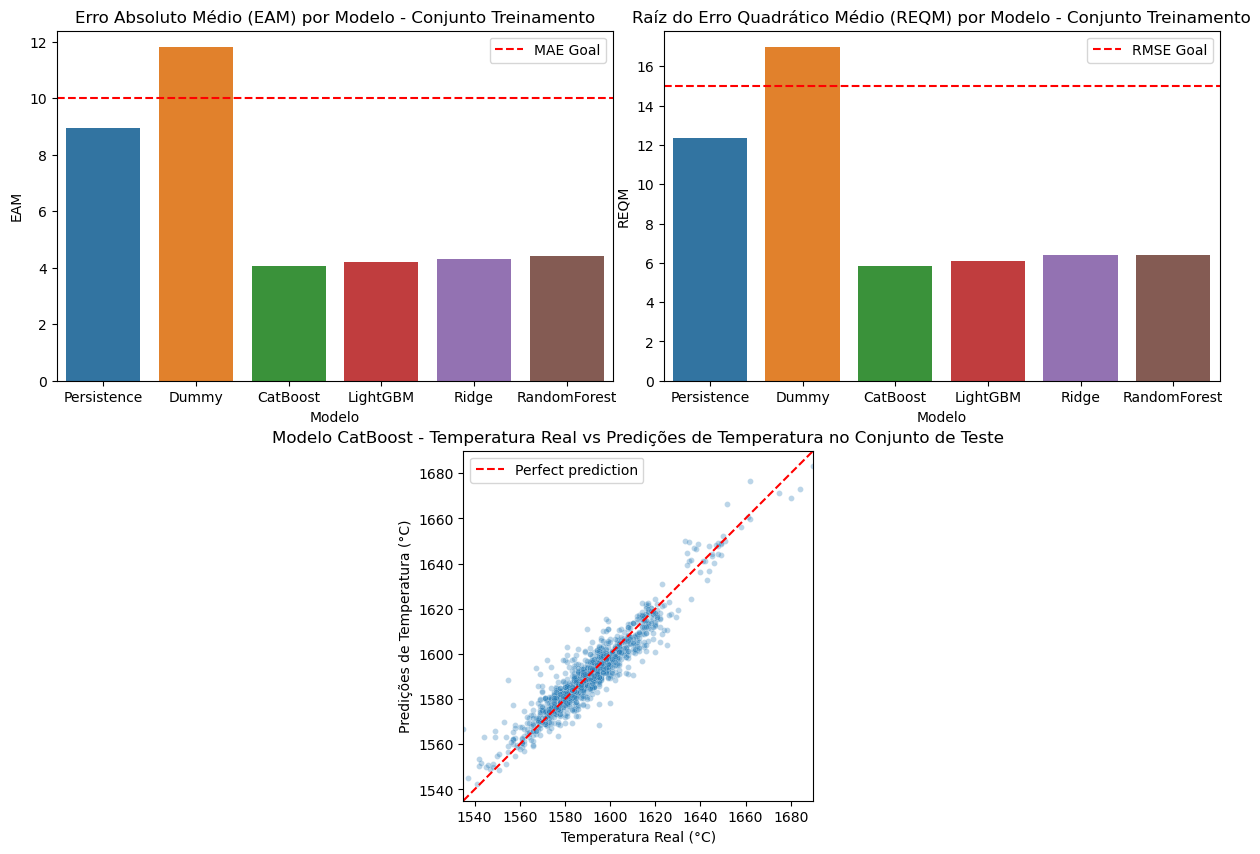

In [10]:
plot_model_diagnostics(test_diagnostics,comparison_df)

O melhor modelo treinado foi CatBoost após uma otimizações de hiperparâmetros que resultou em EAM de $4.042^oC$ e REQM de $5.824^oC$ nos dados de treinamento. Nos dados reservados para teste, esse mesmo modelo obteve EAM $3.927^oC$ e REQM $5.584^oC$. O modelo ficou bem abaixo dos nossos KPIs de $10^oC$ e $15^oC$ para EAM e REQM respectivamente. No KPI de Melhora comparada com Baseline, nosso modelo também se mostrou eficaz, com uma melhora de 54.88% em dados de Treinamento e 59.25% em dados de teste. Esses valores foram calculados diretamente dos EAM e REQM do modelo de persistência no conjunto de testes que resultou em valores de $9.64^oC$ e $13.23^oC$ respectivamente. Os hiperparâmetros que encontramos como melhores foram 900 iterações, depth = 4 e learning_rate = 0.05.

Ainda assim, houveram limitações. Nosso modelo tem alguns erros muito altos para algumas de suas predições, embora essas não sejam tão comuns. Foram observados alguns erros maiores em intervalos de maior duração, mas esses intervalos são menos representados nos dados, o que limita nossa capacidade de avaliar essa relação. Os erros também são mais concentrados para os lotes com ciclos de aquecimento se comparados aos Intervalos que tem adições de materiais mas não tem ciclos de aquecimento. Esses Intervalos também são menos comuns.

Como etapa inicial de validação operacional, sugere-se priorizar intervalos com ciclos de aquecimento e duração de até 30 minutos, por serem condições mais representadas nos dados. Essa seleção não garante a confiabilidade das previsões e deverá ser acompanhada de medições diretas para avaliação de desempenho.

Por fim, a performance precisa ser avaliada por especialistas do campo para entender se existem riscos e limitações da operacionalização de tal Sensor Virtual como eventual substituto a medições manuais uma vez que é preciso definir as limitações metalúrgicas explicitamente para definir se o desempenho do modelo está adequado.

## 5. Impacto no Negócio

O principal objetivo de negócio da Steelproof é reduzir os custos do processo de refino secundário, especialmente aqueles relacionados ao consumo de energia elétrica. Embora tenhamos desenvolvido um modelo com bom desempenho preditivo, ainda não podemos estimar quanto a empresa poderia economizar com sua utilização. Nosso modelo estima temperaturas, mas não calcula diretamente o consumo elétrico nem determina as condições ideais de aquecimento.

1. Sensor Virtual:
   
   Uma das possibilidades de aplicação do sensor virtual seria reduzir a necessidade de algumas medições manuais de temperatura. Isso poderia diminuir os custos associados às medições e, dependendo de como elas são realizadas, o tempo gasto durante o processo. Seria necessário conhecer o custo e a frequência dessas medições, além de determinar em quais situações as previsões poderiam substituí-las sem comprometer a qualidade do aço ou a segurança operacional. Como determinamos em nosso plano inicial do projeto, esse conjunto de dados apresenta 3.216 Lotes de Refino Secundário com um total de 15.907 medições de temperatura, totalizando uma média de 4.95 medições por Lote. Se for possível usar o modelo como um sensor virtual para reduzir a média em 1 medição por Lote, isso resultaria em 3.216 medições a menos, ou seja, uma redução de 20% em todas as medições feitas no período analisado. Nesse cenário, com o tempo e custo de cada medição informados pela Steelproof, isso poedria ser revertido em um cálculo de horas de processo e reais economizados em medições.



2. Futuro -> Otimização de Ciclos de Aquecimento:

   Outra possibilidade para o modelo seria utilizar as estimativas de temperatura para apoiar as decisões relacionadas ao aquecimento. Com informações mais frequentes sobre a temperatura do aço, os operadores poderiam, futuramente, identificar situações em que um novo ciclo de aquecimento talvez não seja necessário. Essa aplicação teria potencial para reduzir o consumo de energia elétrica, mas nosso experimento não permite afirmar que essa redução realmente ocorreria.

Para avaliar concretamente os possíveis benefícios do modelo, precisaríamos de informações adicionais sobre o consumo elétrico, os custos das medições, as características dos diferentes tipos de aço e as decisões operacionais tomadas durante o refino. Também seria necessário considerar os custos de implantação e manutenção do próprio sensor virtual.

Portanto, o impacto econômico identificado neste projeto ainda é qualitativo. Demonstramos que é possível obter estimativas de temperatura com erro médio significativamente inferior ao de um modelo de Persistência, mas a transformação dessa capacidade preditiva em economia para a Steelproof depende de testes operacionais e de uma avaliação dos custos e benefícios envolvidos.

## 6. Conclusões e Recomendações

O projeto demonstrou que é possível utilizar os registros disponíveis para desenvolver um modelo preditivo de temperatura do aço durante o refino secundário. O CatBoost apresentou o melhor desempenho entre os modelos avaliados, com EAM de 3,93°C no conjunto de teste e uma redução de 59,25% no erro em relação ao modelo de Persistência. Todos os limiares de desempenho definidos para o projeto foram atingidos.

Consideramos esses resultados satisfatórios para uma primeira versão experimental do sensor virtual. Entretanto, o bom desempenho nos dados históricos não significa que o modelo já esteja preparado para substituir medições diretas de temperatura. Além de não conhecermos as tolerâncias operacionais da Steelproof, o modelo foi desenvolvido a partir de intervalos delimitados por medições reais, e seu desempenho em instantes arbitrários ainda não foi validado.

Nossa principal recomendação é realizar uma etapa de validação operacional em que o modelo funcione paralelamente às medições diretas, sem substituí-las inicialmente. Poderíamos começar pelos intervalos com ciclos de aquecimento e duração de até 30 minutos, por serem condições mais representadas nos dados utilizados. Essa avaliação permitiria identificar os erros em situações reais e verificar, junto às equipes de operação e controle de qualidade, quais seriam os limites aceitáveis para cada processo.

Também recomendamos melhorar a coleta de dados, principalmente em relação à purga de gás, às características dos diferentes tipos de aço e às informações sobre potência e consumo elétrico. Esses dados poderiam ajudar no desenvolvimento de versões futuras do modelo e permitir uma investigação mais completa sobre o potencial de economia de energia.

Somente após essa validação seria possível decidir em quais situações o sensor virtual poderia ser utilizado como referência operacional e se sua implantação traria benefícios econômicos suficientes para justificar os custos e riscos envolvidos.

## 7. Detalhes Técnicos

Para RandomForestRegressor, fizemos o uso de imputação por estarmos usando a versão 0.24.1 de Scikit-Learn em que RandomForestRegressor não pode receber valores nulos.